# Permutation Hypothesis Test: Cancellation and Churn

We want to see if users with a non-cancellation transaction after their latest cancellation have a different churn rate. We expect their churn rate to be lower.


## 1. State the hypotheses

- **H0:** Churn labels are exchangeable between the two groups. Both groups have the same churn probability.
- **H1:** The two groups have different churn probabilities.

We use a two-sided permutation test with a significance level of **0.05**.


## 2. Load the data and define the groups

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("kkbox_v2_final2.csv")

# Only keep users who canceled before and have a valid group value.
users = df[(df["ever_cancel"] == 1) &
           df["noncancel_after_last_cancel"].isin([0, 1])]

# Group 0: no later non-cancellation transaction.
# Group 1: a later non-cancellation transaction.
summary = users.groupby("noncancel_after_last_cancel")["is_churn"].agg(
    count="size", churned="sum", churn_rate="mean"
)
display(summary.round(4))


                             count  churned  churn_rate
noncancel_after_last_cancel                            
0.0                          21844    14506      0.6641
1.0                           6115     1297      0.2121

## 3. Calculate the observed statistic

Our test statistic is the churn rate of Group 1 minus the churn rate of Group 0. A negative value means Group 1 has a lower churn rate.


In [2]:
p0 = summary.loc[0, "churn_rate"]
p1 = summary.loc[1, "churn_rate"]
observed = p1 - p0

print(f"Group 0 churn rate: {p0:.2%}")
print(f"Group 1 churn rate: {p1:.2%}")
print(f"Observed difference: {observed * 100:.2f} percentage points")


Group 0 churn rate: 66.41%
Group 1 churn rate: 21.21%
Observed difference: -45.20 percentage points


## 4. Simulate under the null hypothesis

Under H0, we can randomly shuffle the churn labels between the groups. We keep the group sizes fixed and calculate a new difference each time. We repeat this **5,000 times** to build the null distribution.


In [3]:
rng = np.random.default_rng(42)
labels = users["is_churn"].to_numpy()
n1 = int(summary.loc[1, "count"])
n_permutations = 5000
permuted_diffs = np.empty(n_permutations)

for i in range(n_permutations):
    shuffled = rng.permutation(labels)
    permuted_diffs[i] = shuffled[:n1].mean() - shuffled[n1:].mean()


## 5. Calculate the p-value

For a two-sided test, we count shuffled differences that are at least as far from zero as the observed difference. We use a +1 correction so the estimated p-value is never zero.


In [4]:
extreme_count = np.sum(np.abs(permuted_diffs) >= abs(observed))
p_value = (extreme_count + 1) / (n_permutations + 1)

print(f"Extreme permutations: {extreme_count} out of {n_permutations}")
print(f"Permutation p-value (+1 correction): {p_value:.5f}")
print("Reject H0" if p_value < 0.05 else "Do not reject H0")


Extreme permutations: 0 out of 5000
Permutation p-value (+1 correction): 0.00020
Reject H0


## 6. Plot the null distribution

The left plot shows the shuffled differences close to zero. The right plot shows the observed difference in red. For the two-sided p-value, both tails beyond the dashed lines count as extreme.


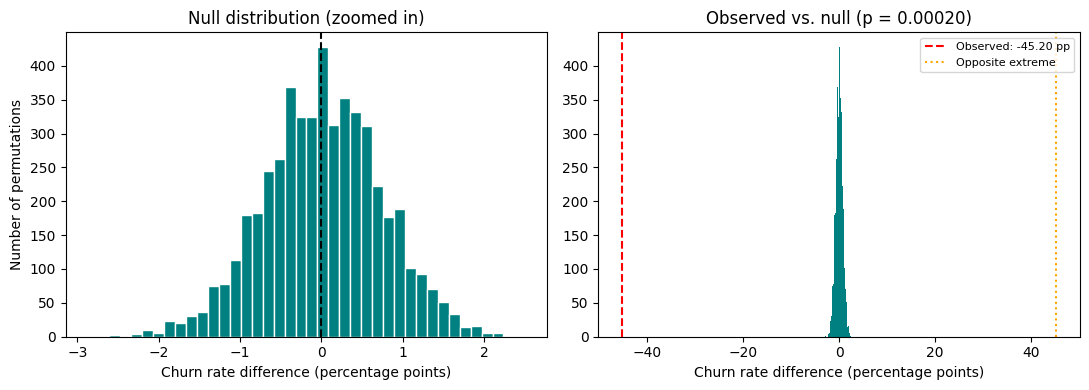

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].hist(permuted_diffs * 100, bins=40, color="teal", edgecolor="white")
axes[0].axvline(0, color="black", linestyle="--")
axes[0].set_title("Null distribution (zoomed in)")
axes[0].set_ylabel("Number of permutations")

axes[1].hist(permuted_diffs * 100, bins=40, color="teal")
axes[1].axvline(observed * 100, color="red", linestyle="--",
                label=f"Observed: {observed * 100:.2f} pp")
axes[1].axvline(-observed * 100, color="orange", linestyle=":",
                label="Opposite extreme")
axes[1].set_xlim(observed * 100 - 5, -observed * 100 + 5)
axes[1].set_title(f"Observed vs. null (p = {p_value:.5f})")
axes[1].legend(fontsize=8)

for ax in axes:
    ax.set_xlabel("Churn rate difference (percentage points)")
plt.tight_layout()
plt.show()


## 7. Conclusion

Group 0 has a churn rate of **66.41%**, while Group 1 has a churn rate of **21.21%**. The observed difference is **-45.20 percentage points**.

None of the 5,000 permutations produced a difference this extreme in either direction. The corrected permutation p-value is **0.00020**, so we reject H0 at the 0.05 level. This is the smallest p-value our simulation can report, not an exact underlying probability.

Our result supports the idea that a later non-cancellation transaction is associated with lower churn among users who canceled before.
